In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-box-plot

**Figure 1: Response lengths of the base model and our RL-trained model on three math datasets.** Each box summarizes 60 responses: boxes span the quartiles with the median as a line, whiskers reach 1.5× the interquartile range, and points mark values beyond the whiskers. RL training lengthens responses on every dataset and most on AIME, where the median grows by 798 tokens (873 → 1670), against 124 tokens on GSM8K.

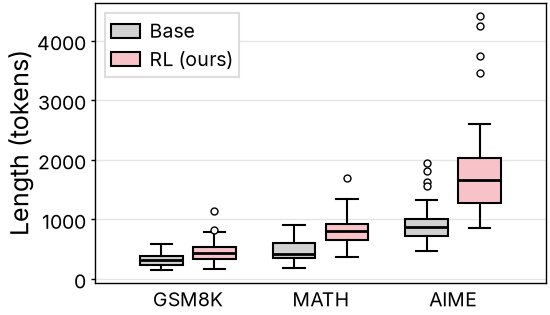

In [2]:
from matplotlib.patches import Patch

with open("../data/grouped-box-plot.json") as f:
    data = json.load(f)
datasets = data["datasets"]
models = [("Base", lighten(colors["neutral"])), ("RL (ours)", lighten(colors["ours"]))]

fig, ax = plt.subplots(figsize=(2.75, 2))
width = 0.8 / len(models)
handles = []
for i, (name, fill) in enumerate(models):
    positions = np.arange(len(datasets)) + (i - (len(models) - 1) / 2) * width
    box = ax.boxplot([data["lengths"][name][d] for d in datasets], positions=positions, widths=0.8 * width)
    for patch in box["boxes"]:
        patch.set_facecolor(fill)
    handles.append(Patch(facecolor=fill, edgecolor="black", linewidth=0.75, label=name))

ax.set_xticks(np.arange(len(datasets)), labels=datasets)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Length (tokens)")
ax.legend(handles=handles, loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/grouped-box-plot.pdf")
fig.savefig("../outputs/grouped-box-plot.png")
plt.show()